# Final figures and analysis tables

Method, field-family, and runtime comparisons from the completed compact and extended runs.

In [1]:
# Resolve the project whether Jupyter starts here or from the repository root.
from collections import defaultdict
import importlib
from math import sqrt
from pathlib import Path
from statistics import fmean, stdev
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from analysis import write_csv
_figures = importlib.reload(importlib.import_module("figures"))
load_case_rows = _figures.load_case_rows
load_summary = _figures.load_summary

STYLES = _figures.STYLES
FAMILY_ORDER = _figures.FAMILY_ORDER

## Results

Load matched full-run results and prepare the output tables and figures.

In [2]:
RESULT_MODE = "full"
STUDIES = ("compact", "extended")
OUTPUT = PROJECT / "results" / "final" / RESULT_MODE
FIGURE_OUTPUT = OUTPUT / "figures"
TABLE_OUTPUT = OUTPUT / "tables"

summaries = {}
case_rows = {}
for study in STUDIES:
    summaries[study] = load_summary(PROJECT, study, mode=RESULT_MODE)
    case_rows[study] = load_case_rows(PROJECT, study, mode=RESULT_MODE)

    dimensions = {int(row["dimension"]) for row in summaries[study]}
    if dimensions != {1, 2}:
        raise RuntimeError(f"The {study} full summary must contain both dimensions")

    expected_methods = (
        {"Exhaustive", "Greedy", "Heuristic", "Uniform", "Random"}
        if study == "compact"
        else {"Greedy", "Heuristic", "Uniform", "Random"}
    )
    observed_methods = {row["method"] for row in summaries[study]}
    if observed_methods != expected_methods:
        raise RuntimeError(
            f"Unexpected methods in {study} full results: {sorted(observed_methods)}"
        )

    print(
        f"Loaded {study}: {len(summaries[study])} summary rows and "
        f"{len(case_rows[study])} case-method-budget rows"
    )

Loaded compact: 40 summary rows and 23700 case-method-budget rows
Loaded extended: 32 summary rows and 68844 case-method-budget rows


## Matched comparisons

Retain case-budget groups completed successfully by every method in each comparison.

In [3]:
PANEL_LAYOUT = (
    ("compact", 1, "(a) One-dimensional compact dataset"),
    ("compact", 2, "(b) Two-dimensional compact dataset"),
    ("extended", 1, "(c) One-dimensional extended dataset"),
    ("extended", 2, "(d) Two-dimensional extended dataset"),
)


def _plot_style():
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 11,
        "mathtext.fontset": "stix",
        "pdf.fonttype": 42,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })


def _error(row):
    return float(row["error_probability"])


def _mean_ci95(values):
    mean = fmean(values)
    half_width = 0.0 if len(values) < 2 else 1.96 * stdev(values) / sqrt(len(values))
    return mean, max(0.0, mean - half_width), min(1.0, mean + half_width)


def _matched_groups(rows):
    methods = {row["method"] for row in rows}
    groups = defaultdict(dict)
    for row in rows:
        key = (row["dataset"], row["case"], int(row["N"]))
        groups[key][row["method"]] = row
    return [
        group for group in groups.values()
        if set(group) == methods
        and all(row["status"] == "ok" for row in group.values())
    ]


def _matched_rows(rows):
    return [row for group in _matched_groups(rows) for row in group.values()]


def _instance_mean_rows(rows):
    grouped = defaultdict(list)
    metadata = {}
    for row in _matched_rows(rows):
        key = (row["dataset"], row["case"], row["method"])
        grouped[key].append(_error(row))
        metadata[key] = row

    averaged = []
    for key, values in grouped.items():
        row = dict(metadata[key])
        row["instance_mean_error"] = fmean(values)
        averaged.append(row)
    return averaged


def _save_figure(figure, name):
    FIGURE_OUTPUT.mkdir(parents=True, exist_ok=True)
    for extension in ("pdf", "png"):
        figure.savefig(
            FIGURE_OUTPUT / f"{name}.{extension}",
            dpi=300,
            bbox_inches="tight",
        )

## Method comparison

Mean error probability by budget fraction for compact and extended datasets in both dimensions.

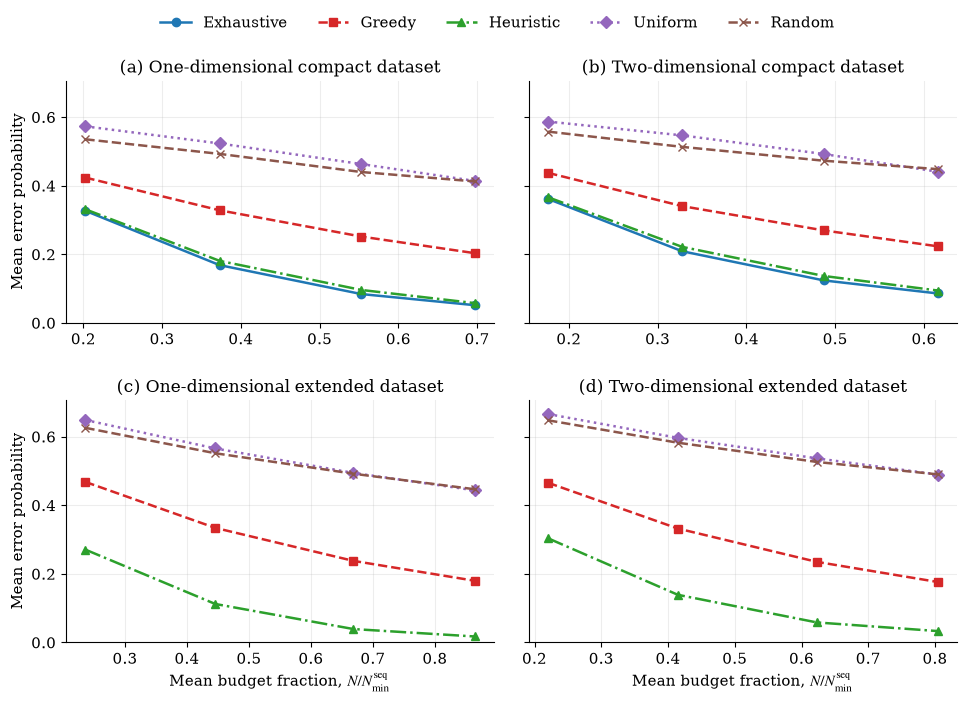

In [4]:
def plot_method_comparison_2x2(summaries):
    _plot_style()
    figure, axes = plt.subplots(2, 2, figsize=(11.5, 7.2), sharey=True)
    maximum = 0.0

    for axis, (study, dimension, title) in zip(axes.flat, PANEL_LAYOUT):
        summary = summaries[study]
        for method, (color, marker, line) in STYLES.items():
            selected = sorted(
                [
                    row for row in summary
                    if int(row["dimension"]) == dimension
                    and row["method"] == method
                ],
                key=lambda row: int(row["budget_level"]),
            )
            if selected:
                errors = [float(row["mean_error_probability"]) for row in selected]
                maximum = max(maximum, *errors)
                axis.plot(
                    [float(row["mean_budget_fraction"]) for row in selected],
                    errors,
                    color=color,
                    marker=marker,
                    linestyle=line,
                    linewidth=1.8,
                    label=method,
                )
        axis.set_title(title, fontsize=12)
        axis.grid(alpha=0.22)

    axes[0, 0].set_ylim(0, min(1.0, maximum + 0.06 * max(maximum, 0.1)))
    for axis in axes[-1, :]:
        axis.set_xlabel(r"Mean budget fraction, $N/N_{\min}^{\mathrm{seq}}$")
    for axis in axes[:, 0]:
        axis.set_ylabel("Mean error probability")

    figure.subplots_adjust(top=0.88, bottom=0.10, hspace=0.32, wspace=0.08)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.99),
        ncol=len(labels),
        frameon=False,
    )
    return figure


method_figure = plot_method_comparison_2x2(summaries)
_save_figure(method_figure, "method_comparison_2x2")
display(method_figure)
plt.close(method_figure)

In [5]:
def method_comparison_table(summaries):
    table = []
    method_columns = {
        "Exhaustive": "exhaustive_mean_error",
        "Greedy": "greedy_mean_error",
        "Heuristic": "heuristic_mean_error",
        "Uniform": "uniform_mean_error",
        "Random": "random_mean_error",
    }
    for study in STUDIES:
        summary = summaries[study]
        for dimension in (1, 2):
            levels = sorted({
                int(row["budget_level"])
                for row in summary if int(row["dimension"]) == dimension
            })
            for level in levels:
                selected = {
                    row["method"]: row
                    for row in summary
                    if int(row["dimension"]) == dimension
                    and int(row["budget_level"]) == level
                }
                greedy = float(selected["Greedy"]["mean_error_probability"])
                heuristic = float(selected["Heuristic"]["mean_error_probability"])
                record = {
                    "study": study,
                    "dimension": dimension,
                    "budget_level": level,
                    "case_count": int(selected["Greedy"]["case_count"]),
                    "mean_budget_fraction": float(selected["Greedy"]["mean_budget_fraction"]),
                }
                for method, column in method_columns.items():
                    record[column] = (
                        float(selected[method]["mean_error_probability"])
                        if method in selected else ""
                    )
                record["heuristic_reduction_vs_greedy_percent"] = (
                    100.0 * (greedy - heuristic) / greedy if greedy else 0.0
                )
                record["heuristic_absolute_gap_from_exhaustive"] = (
                    abs(
                        heuristic
                        - float(selected["Exhaustive"]["mean_error_probability"])
                    )
                    if "Exhaustive" in selected else ""
                )
                table.append(record)
    return table


def method_overview_table(rows):
    overview = []
    for study in STUDIES:
        for dimension in (1, 2):
            selected = [
                row for row in rows
                if row["study"] == study and row["dimension"] == dimension
            ]
            reductions = [
                row["heuristic_reduction_vs_greedy_percent"] for row in selected
            ]
            gaps = [
                row["heuristic_absolute_gap_from_exhaustive"]
                for row in selected
                if row["heuristic_absolute_gap_from_exhaustive"] != ""
            ]
            overview.append({
                "study": study,
                "dimension": dimension,
                "minimum_reduction_vs_greedy_percent": min(reductions),
                "maximum_reduction_vs_greedy_percent": max(reductions),
                "mean_absolute_gap_from_exhaustive": fmean(gaps) if gaps else "",
            })
    return overview


def method_comparison_markdown(rows):
    lines = [
        "| Study | Dimension | Budget | Cases | Mean budget fraction | Exhaustive | Greedy | Heuristic | Uniform | Random | Heuristic reduction vs. Greedy (%) | Heuristic gap from Exhaustive |",
        "|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
    ]
    for row in rows:
        exhaustive = row["exhaustive_mean_error"]
        gap = row["heuristic_absolute_gap_from_exhaustive"]
        lines.append(
            f"| {row['study'].title()} | {row['dimension']}D | {row['budget_level']} | "
            f"{row['case_count']} | {row['mean_budget_fraction']:.4f} | "
            f"{exhaustive:.4f} | " if exhaustive != "" else
            f"| {row['study'].title()} | {row['dimension']}D | {row['budget_level']} | "
            f"{row['case_count']} | {row['mean_budget_fraction']:.4f} | -- | "
        )
        lines[-1] += (
            f"{row['greedy_mean_error']:.4f} | {row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | {row['random_mean_error']:.4f} | "
            f"{row['heuristic_reduction_vs_greedy_percent']:.1f} | "
            f"{gap:.4f} |" if gap != "" else
            f"{row['greedy_mean_error']:.4f} | {row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | {row['random_mean_error']:.4f} | "
            f"{row['heuristic_reduction_vs_greedy_percent']:.1f} | -- |"
        )
    return "\n".join(lines)


def method_overview_markdown(rows):
    lines = [
        "| Study | Dimension | Heuristic reduction vs. Greedy (%) | Mean absolute gap from Exhaustive |",
        "|---|---:|---:|---:|",
    ]
    for row in rows:
        gap = row["mean_absolute_gap_from_exhaustive"]
        gap_text = "--" if gap == "" else f"{gap:.4f}"
        lines.append(
            f"| {row['study'].title()} | {row['dimension']}D | "
            f"{row['minimum_reduction_vs_greedy_percent']:.1f}--"
            f"{row['maximum_reduction_vs_greedy_percent']:.1f} | {gap_text} |"
        )
    return "\n".join(lines)


method_rows = method_comparison_table(summaries)
method_overview = method_overview_table(method_rows)
write_csv(TABLE_OUTPUT / "method_comparison_by_budget.csv", method_rows)
write_csv(TABLE_OUTPUT / "method_comparison_overview.csv", method_overview)

display(Markdown("### Method-comparison overview"))
display(Markdown(method_overview_markdown(method_overview)))
display(Markdown("### Method-comparison values by budget"))
display(Markdown(method_comparison_markdown(method_rows)))

### Method-comparison overview

| Study | Dimension | Heuristic reduction vs. Greedy (%) | Mean absolute gap from Exhaustive |
|---|---:|---:|---:|
| Compact | 1D | 21.8--71.6 | 0.0087 |
| Compact | 2D | 16.3--57.7 | 0.0098 |
| Extended | 1D | 42.2--90.3 | -- |
| Extended | 2D | 34.8--81.2 | -- |

### Method-comparison values by budget

| Study | Dimension | Budget | Cases | Mean budget fraction | Exhaustive | Greedy | Heuristic | Uniform | Random | Heuristic reduction vs. Greedy (%) | Heuristic gap from Exhaustive |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Compact | 1D | 1 | 600 | 0.2026 | 0.3268 | 0.4237 | 0.3312 | 0.5731 | 0.5353 | 21.8 | 0.0044 |
| Compact | 1D | 2 | 600 | 0.3730 | 0.1685 | 0.3284 | 0.1809 | 0.5232 | 0.4928 | 44.9 | 0.0124 |
| Compact | 1D | 3 | 594 | 0.5530 | 0.0841 | 0.2518 | 0.0961 | 0.4631 | 0.4399 | 61.8 | 0.0120 |
| Compact | 1D | 4 | 573 | 0.6972 | 0.0517 | 0.2033 | 0.0577 | 0.4139 | 0.4125 | 71.6 | 0.0060 |
| Compact | 2D | 1 | 600 | 0.1767 | 0.3613 | 0.4374 | 0.3662 | 0.5870 | 0.5577 | 16.3 | 0.0049 |
| Compact | 2D | 2 | 600 | 0.3275 | 0.2090 | 0.3406 | 0.2218 | 0.5468 | 0.5133 | 34.9 | 0.0128 |
| Compact | 2D | 3 | 597 | 0.4871 | 0.1239 | 0.2697 | 0.1368 | 0.4924 | 0.4729 | 49.3 | 0.0130 |
| Compact | 2D | 4 | 576 | 0.6154 | 0.0859 | 0.2234 | 0.0945 | 0.4408 | 0.4484 | 57.7 | 0.0085 |
| Extended | 1D | 1 | 2160 | 0.2361 | -- | 0.4679 | 0.2706 | 0.6486 | 0.6257 | 42.2 | -- |
| Extended | 1D | 2 | 2160 | 0.4456 | -- | 0.3340 | 0.1122 | 0.5656 | 0.5516 | 66.4 | -- |
| Extended | 1D | 3 | 2155 | 0.6686 | -- | 0.2378 | 0.0390 | 0.4942 | 0.4919 | 83.6 | -- |
| Extended | 1D | 4 | 2127 | 0.8645 | -- | 0.1797 | 0.0174 | 0.4433 | 0.4466 | 90.3 | -- |
| Extended | 2D | 1 | 2160 | 0.2204 | -- | 0.4654 | 0.3035 | 0.6658 | 0.6476 | 34.8 | -- |
| Extended | 2D | 2 | 2160 | 0.4146 | -- | 0.3321 | 0.1390 | 0.5965 | 0.5823 | 58.2 | -- |
| Extended | 2D | 3 | 2159 | 0.6228 | -- | 0.2350 | 0.0584 | 0.5368 | 0.5263 | 75.2 | -- |
| Extended | 2D | 4 | 2130 | 0.8040 | -- | 0.1763 | 0.0331 | 0.4896 | 0.4900 | 81.2 | -- |

## Field-family comparison

Mean instance-level error by field family with 95% confidence intervals.

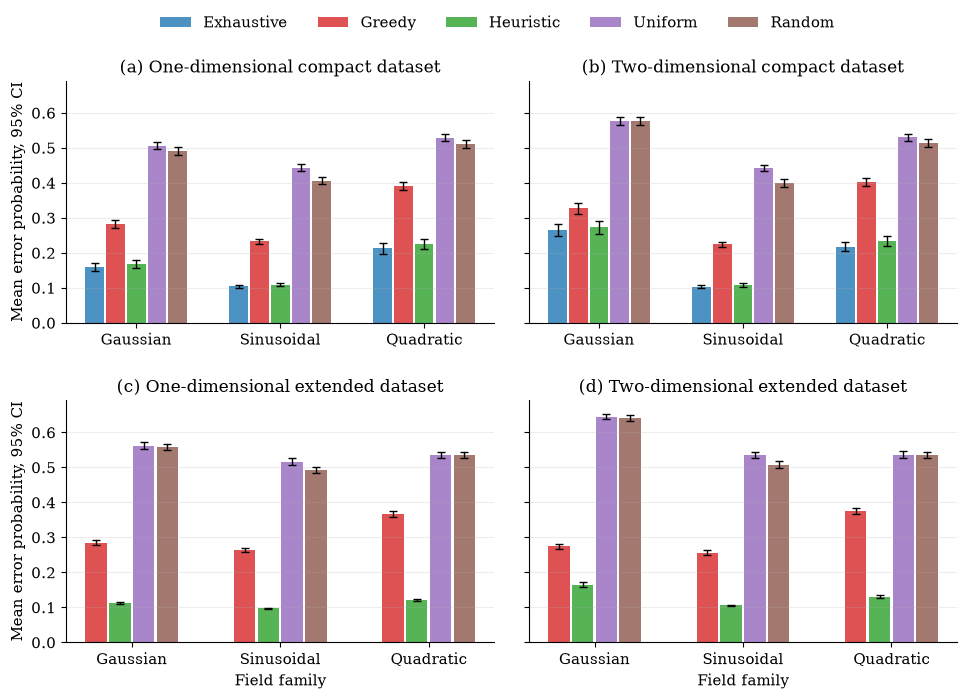

In [6]:
def field_family_table(case_rows):
    table = []
    for study in STUDIES:
        instance_means = _instance_mean_rows(case_rows[study])
        for dimension in (1, 2):
            selected = [
                row for row in instance_means if int(row["dimension"]) == dimension
            ]
            for family in FAMILY_ORDER:
                for method in STYLES:
                    values = [
                        float(row["instance_mean_error"]) for row in selected
                        if row["field_family"] == family
                        and row["method"] == method
                    ]
                    if not values:
                        continue
                    mean, low, high = _mean_ci95(values)
                    table.append({
                        "study": study,
                        "dimension": dimension,
                        "field_family": family,
                        "method": method,
                        "observations": len(values),
                        "mean_error_probability": mean,
                        "ci95_low": low,
                        "ci95_high": high,
                    })
    return table


def plot_field_family_2x2(family_rows):
    _plot_style()
    figure, axes = plt.subplots(2, 2, figsize=(11.5, 7.2), sharey=True)
    maximum = 0.0

    for axis, (study, dimension, title) in zip(axes.flat, PANEL_LAYOUT):
        panel = [
            row for row in family_rows
            if row["study"] == study and row["dimension"] == dimension
        ]
        methods = [
            method for method in STYLES
            if any(row["method"] == method for row in panel)
        ]
        positions = list(range(1, len(FAMILY_ORDER) + 1))
        width = min(0.16, 0.72 / len(methods))
        offsets = [
            (index - (len(methods) - 1) / 2) * width
            for index in range(len(methods))
        ]

        for method, offset in zip(methods, offsets):
            means, lower, upper = [], [], []
            for family in FAMILY_ORDER:
                row = next(
                    row for row in panel
                    if row["method"] == method
                    and row["field_family"] == family
                )
                mean = row["mean_error_probability"]
                means.append(mean)
                lower.append(mean - row["ci95_low"])
                upper.append(row["ci95_high"] - mean)
                maximum = max(maximum, row["ci95_high"])
            axis.bar(
                [position + offset for position in positions],
                means,
                width=0.9 * width,
                yerr=[lower, upper],
                capsize=3,
                color=STYLES[method][0],
                alpha=0.8,
                label=method,
                error_kw={"elinewidth": 1, "ecolor": "black"},
            )

        axis.set_title(title, fontsize=12)
        axis.set_xticks(positions, [family.title() for family in FAMILY_ORDER])
        axis.grid(axis="y", alpha=0.22)

    upper_limit = min(1.0, maximum + 0.06 * max(maximum, 0.1))
    axes[0, 0].set_ylim(0, upper_limit)
    for axis in axes[-1, :]:
        axis.set_xlabel("Field family")
    for axis in axes[:, 0]:
        axis.set_ylabel("Mean error probability, 95% CI")

    figure.subplots_adjust(top=0.88, bottom=0.10, hspace=0.32, wspace=0.08)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.99),
        ncol=len(labels),
        frameon=False,
    )
    return figure


family_rows = field_family_table(case_rows)
family_figure = plot_field_family_2x2(family_rows)
_save_figure(family_figure, "field_family_2x2")
display(family_figure)
plt.close(family_figure)

In [7]:
def field_family_markdown(rows):
    index = {
        (row["study"], row["dimension"], row["field_family"], row["method"]): row
        for row in rows
    }
    lines = [
        "| Study | Dimension | Field family | Observations | Exhaustive | Greedy | Heuristic | Uniform | Random |",
        "|---|---:|---|---:|---:|---:|---:|---:|---:|",
    ]
    for study in STUDIES:
        for dimension in (1, 2):
            for family in FAMILY_ORDER:
                available = {
                    method: index.get((study, dimension, family, method))
                    for method in STYLES
                }
                first = next(row for row in available.values() if row is not None)
                values = []
                for method in STYLES:
                    row = available[method]
                    values.append(
                        "--" if row is None else
                        f"{row['mean_error_probability']:.4f} "
                        f"[{row['ci95_low']:.4f}, {row['ci95_high']:.4f}]"
                    )
                lines.append(
                    f"| {study.title()} | {dimension}D | {family.title()} | "
                    f"{first['observations']} | " + " | ".join(values) + " |"
                )
    return "\n".join(lines)


write_csv(TABLE_OUTPUT / "field_family_error.csv", family_rows)
display(Markdown("### Field-family means and 95% confidence intervals"))
display(Markdown(field_family_markdown(family_rows)))

print("Final figures:", FIGURE_OUTPUT)
print("Analysis tables:", TABLE_OUTPUT)
print("Source Compact results retained at:", PROJECT / "results" / "compact" / "full")
print("Source Extended results retained at:", PROJECT / "results" / "extended" / "full")

### Field-family means and 95% confidence intervals

| Study | Dimension | Field family | Observations | Exhaustive | Greedy | Heuristic | Uniform | Random |
|---|---:|---|---:|---:|---:|---:|---:|---:|
| Compact | 1D | Gaussian | 200 | 0.1598 [0.1487, 0.1709] | 0.2819 [0.2712, 0.2927] | 0.1681 [0.1568, 0.1795] | 0.5065 [0.4957, 0.5173] | 0.4913 [0.4801, 0.5025] |
| Compact | 1D | Sinusoidal | 200 | 0.1045 [0.0997, 0.1092] | 0.2332 [0.2263, 0.2402] | 0.1095 [0.1046, 0.1143] | 0.4438 [0.4338, 0.4537] | 0.4065 [0.3960, 0.4170] |
| Compact | 1D | Quadratic | 200 | 0.2125 [0.1979, 0.2270] | 0.3910 [0.3784, 0.4036] | 0.2249 [0.2100, 0.2399] | 0.5288 [0.5185, 0.5391] | 0.5105 [0.4989, 0.5222] |
| Compact | 2D | Gaussian | 200 | 0.2653 [0.2476, 0.2830] | 0.3277 [0.3117, 0.3436] | 0.2725 [0.2545, 0.2904] | 0.5762 [0.5646, 0.5878] | 0.5764 [0.5645, 0.5883] |
| Compact | 2D | Sinusoidal | 200 | 0.1034 [0.0985, 0.1083] | 0.2239 [0.2177, 0.2301] | 0.1088 [0.1038, 0.1139] | 0.4422 [0.4332, 0.4511] | 0.3998 [0.3889, 0.4106] |
| Compact | 2D | Quadratic | 200 | 0.2177 [0.2047, 0.2308] | 0.4013 [0.3898, 0.4129] | 0.2343 [0.2208, 0.2478] | 0.5305 [0.5200, 0.5410] | 0.5145 [0.5029, 0.5262] |
| Extended | 1D | Gaussian | 720 | -- | 0.2853 [0.2784, 0.2921] | 0.1130 [0.1098, 0.1162] | 0.5621 [0.5530, 0.5712] | 0.5579 [0.5491, 0.5666] |
| Extended | 1D | Sinusoidal | 720 | -- | 0.2639 [0.2569, 0.2710] | 0.0971 [0.0947, 0.0994] | 0.5162 [0.5067, 0.5257] | 0.4929 [0.4843, 0.5015] |
| Extended | 1D | Quadratic | 720 | -- | 0.3660 [0.3576, 0.3743] | 0.1210 [0.1175, 0.1245] | 0.5350 [0.5255, 0.5446] | 0.5349 [0.5256, 0.5443] |
| Extended | 2D | Gaussian | 720 | -- | 0.2742 [0.2675, 0.2809] | 0.1646 [0.1579, 0.1713] | 0.6448 [0.6371, 0.6525] | 0.6408 [0.6328, 0.6489] |
| Extended | 2D | Sinusoidal | 720 | -- | 0.2566 [0.2499, 0.2634] | 0.1060 [0.1039, 0.1081] | 0.5352 [0.5257, 0.5448] | 0.5080 [0.4991, 0.5169] |
| Extended | 2D | Quadratic | 720 | -- | 0.3763 [0.3677, 0.3850] | 0.1310 [0.1275, 0.1345] | 0.5359 [0.5262, 0.5455] | 0.5350 [0.5255, 0.5445] |

Final figures: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/final/full/figures
Analysis tables: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/final/full/tables
Source Compact results retained at: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/compact/full
Source Extended results retained at: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/extended/full


## Compact runtime comparison

Mean runtime for Exhaustive, Greedy, and Heuristic by dimension and $K$.

In [8]:
def compact_runtime_table(rows):
    methods = ("Exhaustive", "Greedy", "Heuristic")
    matched = _matched_rows(rows)
    grouped = defaultdict(list)
    for row in matched:
        if row["method"] in methods:
            key = (int(row["dimension"]), int(row["K"]), row["method"])
            grouped[key].append(float(row["seconds"]))

    table = []
    for dimension in (1, 2):
        K_values = sorted({
            int(row["K"]) for row in matched
            if int(row["dimension"]) == dimension
        })
        for K in K_values:
            values = {
                method: grouped[(dimension, K, method)] for method in methods
            }
            counts = {len(method_values) for method_values in values.values()}
            if len(counts) != 1:
                raise RuntimeError(
                    f"Runtime comparison is not matched for dimension={dimension}, K={K}"
                )
            means = {
                method: fmean(method_values)
                for method, method_values in values.items()
            }
            table.append({
                "dimension": dimension,
                "K": K,
                "evaluations_per_method": counts.pop(),
                "exhaustive_mean_seconds": means["Exhaustive"],
                "greedy_mean_seconds": means["Greedy"],
                "heuristic_mean_seconds": means["Heuristic"],
                "exhaustive_to_greedy_ratio": (
                    means["Exhaustive"] / means["Greedy"]
                ),
                "exhaustive_to_heuristic_ratio": (
                    means["Exhaustive"] / means["Heuristic"]
                ),
            })
    return table


def compact_runtime_markdown(rows):
    lines = [
        "| Dimension | $K$ | Evaluations per method | Exhaustive (s) | Greedy (s) | Heuristic (s) | Exhaustive / Greedy | Exhaustive / Heuristic |",
        "|---|---:|---:|---:|---:|---:|---:|---:|",
    ]
    for row in rows:
        lines.append(
            f"| {row['dimension']}D | {row['K']} | "
            f"{row['evaluations_per_method']} | "
            f"{row['exhaustive_mean_seconds']:.6f} | "
            f"{row['greedy_mean_seconds']:.6f} | "
            f"{row['heuristic_mean_seconds']:.6f} | "
            f"{row['exhaustive_to_greedy_ratio']:.1f}x | "
            f"{row['exhaustive_to_heuristic_ratio']:.1f}x |"
        )
    return "\n".join(lines)


compact_runtime_rows = compact_runtime_table(case_rows["compact"])
write_csv(
    TABLE_OUTPUT / "compact_runtime_comparison.csv",
    compact_runtime_rows,
)
display(Markdown(compact_runtime_markdown(compact_runtime_rows)))

| Dimension | $K$ | Evaluations per method | Exhaustive (s) | Greedy (s) | Heuristic (s) | Exhaustive / Greedy | Exhaustive / Heuristic |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 1168 | 0.025839 | 0.000231 | 0.000587 | 111.8x | 44.0x |
| 1D | 4 | 1199 | 1.156406 | 0.000540 | 0.001577 | 2142.0x | 733.5x |
| 2D | 3 | 1173 | 0.027666 | 0.000231 | 0.000591 | 119.8x | 46.8x |
| 2D | 4 | 1200 | 1.174355 | 0.000532 | 0.001555 | 2205.8x | 755.4x |

## Extended runtime comparison

Mean Greedy and Heuristic runtime by $K$ for both dimensions.

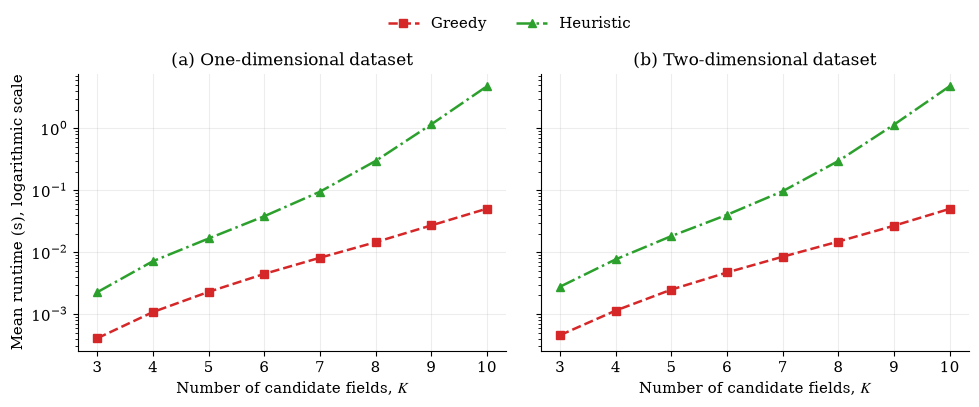

In [9]:
def _runtime_instance_means(rows):
    methods = ("Greedy", "Heuristic")
    grouped_runs = defaultdict(dict)
    for row in rows:
        if row["method"] in methods:
            key = (row["dataset"], row["case"], int(row["N"]))
            grouped_runs[key][row["method"]] = row

    matched_runs = [
        group for group in grouped_runs.values()
        if set(group) == set(methods)
        and all(row["status"] == "ok" for row in group.values())
    ]

    grouped_instances = defaultdict(list)
    metadata = {}
    for group in matched_runs:
        for method, row in group.items():
            key = (
                row["dataset"],
                row["case"],
                int(row["dimension"]),
                int(row["K"]),
                method,
            )
            grouped_instances[key].append(float(row["seconds"]))
            metadata[key] = row

    instance_means = []
    for key, values in grouped_instances.items():
        row = metadata[key]
        instance_means.append({
            "dataset": row["dataset"],
            "case": row["case"],
            "dimension": int(row["dimension"]),
            "K": int(row["K"]),
            "method": row["method"],
            "mean_seconds": fmean(values),
        })
    return instance_means


def plot_extended_runtime(rows):
    instance_means = _runtime_instance_means(rows)
    _plot_style()
    figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
    titles = {
        1: "(a) One-dimensional dataset",
        2: "(b) Two-dimensional dataset",
    }

    for axis, dimension in zip(axes, (1, 2)):
        selected = [
            row for row in instance_means if row["dimension"] == dimension
        ]
        K_values = sorted({row["K"] for row in selected})
        for method in ("Greedy", "Heuristic"):
            means = [
                fmean(
                    row["mean_seconds"] for row in selected
                    if row["K"] == K and row["method"] == method
                )
                for K in K_values
            ]
            color, marker, line = STYLES[method]
            axis.plot(
                K_values,
                means,
                color=color,
                marker=marker,
                linestyle=line,
                linewidth=1.8,
                label=method,
            )
        axis.set_title(titles[dimension], fontsize=12)
        axis.set_xlabel(r"Number of candidate fields, $K$")
        axis.set_yscale("log")
        axis.grid(alpha=0.22)

    axes[0].set_ylabel("Mean runtime (s), logarithmic scale")
    figure.subplots_adjust(top=0.82, bottom=0.16, wspace=0.08)
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.99),
        ncol=2,
        frameon=False,
    )
    return figure


runtime_figure = plot_extended_runtime(case_rows["extended"])
_save_figure(runtime_figure, "extended_runtime_by_k")
display(runtime_figure)
plt.close(runtime_figure)